<a href="https://colab.research.google.com/github/chegeveronica/Space-week-projects/blob/main/Multi_Satellite_Orbit_Propagation%2C.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Multi-Satellite Orbit Propagation & Visualization Dashboard

Welcome to the **Multi-Satellite Orbit Propagation and Visualization** workspace. This project implements a high-precision numerical orbit propagator, visualizes global ground tracks, calculates orbital mechanics telemetry, and exports analytical reports and interactive KML geographic models directly to Google Earth.

## 🛰️ Project Overview

This project provides an end-to-end framework for modeling orbits using classic Keplerian elements and rotating them into the Earth-Centered Earth-Fixed (ECEF) frame. It features live data integration with **CelesTrak** to import real-time spacecraft orbits such as Galileo, GPS, Starlink, and more.

---

## 🗺️ Pipeline Architecture (Step-by-Step)

### 1. **Stage 1: Setup & Configuration**
Defines global variables, astrophysical constants ($G\cdot M_{Earth}$, radius of Earth), and establishes the file hierarchy paths (`/content/satellite_orbits/input` & `/output`).

### 2. **Stage 2: Input Extraction & Schema Verification**
Imports local files containing world maps and historical orbital element snapshots from zipped archives. Validates structural and numerical data types to ensure reliable processing.

### 3. **Stage 3: Element Parsing**
Converts native orbital records (specifically CelesTrak GP OMM JSON fields) into physical model parameters (converting Mean Motion to semi-major axis $a$ via Kepler's Third Law, angles to radians, and epoch timestamps to UTC format).

### 4. **Stage 4: Unified Time Grid Generation**
Constructs a synchronized, 24-hour UTC grid at a 5-second step frequency beginning at the most recently updated spacecraft epoch. Stale data parameters (older than 7 days) are automatically identified and flagged.

### 5. **Stage 5: High-Precision Keplerian Propagation**
Solves Kepler's transcendental equation ($M = E - e\sin E$) utilizing a high-efficiency **Newton-Raphson numerical solver**. Position vectors are calculated inside the inertial frame and dynamically rotated into the rotating Earth frame (ECEF) using Greenwich Mean Sidereal Time (GMST) calculations.

### 6. **Stage 6: Telemetry & Statistical Analysis**
Calculates derived orbital statistics for every satellite, verifying perigee, apogee, orbital period, as well as velocity extremes (minimum and maximum speeds via the Vis-Viva equation).

### 7. **Stage 7: Cartographic Ground Track & Speed Profile Visualizations**
Plots 2D ground track coordinate vectors over a geographic coastline matrix and outputs custom timeline series detailing variations in orbital velocities.

### 8. **Stage 8: Interactive Geobrowser Exports**
Compiles physical metrics into an analytical TXT report, formats ECEF coordinates into static 3D spatial tracks (`.kml`), generates time-animated trajectories mapped directly to real clock values (`.kml`), and packages all artifacts into a single downloadable ZIP archive.

### 9. **Live CelesTrak Extension**
Features an integrated client module to download current live orbit parameters directly from CelesTrak APIs. It respects API server rate boundaries through local file-system caching (2-hour TTL).

---

## 🚀 Getting Started

### Prerequisites
Make sure you have the following packages installed (standard in Colab runtimes):
```bash
pip install matplotlib requests
```

### Running the Project
1. Run **Stage 1** to initialize the folder structures.
2. When prompted in **Stage 2**, upload your workspace input ZIP file (`orbit_workshop_inputs.zip`) to your workspace environment.
3. Run Stages 3 through 8 sequentially to propagate orbits, generate figures, and automatically trigger the download of your analytical reports and KML bundles.
4. (Optional) Run the **Live CelesTrak Data** cell to query actual, real-time satellite telemetry.

---

## 🌐 Visualizing Results in Google Earth
1. Locate and extract the downloaded `satellite_orbit_outputs.zip` file.
2. Open [Google Earth Web](https://earth.google.com/web/) or Google Earth Pro.
3. Go to **Projects** -> **New Project** -> **Import KML file from computer**.
4. Upload `orbit_tracks_ecef.kml` to inspect the 3D orbit shells, or upload `orbit_animation.kml` to watch the satellites move across their ground tracks in real time!

In [35]:
# Stage 1: Setup and Configuration
import json
import math
import time
import zipfile
import xml.etree.ElementTree as ET
from datetime import datetime, timedelta, timezone
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import requests
from google.colab import files

# Constants
MU_EARTH_KM3_S2 = 398600.4418
EARTH_RADIUS_KM = 6378.137

# Directories inside /content/satellite_orbits
BASE_DIR = Path('/content/satellite_orbits')
IN_DIR = BASE_DIR / 'input'
OUT_DIR = BASE_DIR / 'output'

IN_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Configuration
STEP_SECONDS = 5
DURATION_HOURS = 24
LIVE_GROUP = 'GALILEO'

# Print configuration to verify setup
print("--- Stage 1: Configuration Setup Success ---")
print(f"MU_EARTH: {MU_EARTH_KM3_S2} km^3/s^2")
print(f"EARTH_RADIUS: {EARTH_RADIUS_KM} km")
print(f"Input Directory: {IN_DIR}")
print(f"Output Directory: {OUT_DIR}")
print(f"Step Seconds: {STEP_SECONDS} s")
print(f"Duration Hours: {DURATION_HOURS} h")
print(f"Live Group: {LIVE_GROUP}")

--- Stage 1: Configuration Setup Success ---
MU_EARTH: 398600.4418 km^3/s^2
EARTH_RADIUS: 6378.137 km
Input Directory: /content/satellite_orbits/input
Output Directory: /content/satellite_orbits/output
Step Seconds: 5 s
Duration Hours: 24 h
Live Group: GALILEO


In [36]:
# Stage 2: Extract Inputs and Load Orbit Data (OMM JSON)

def extract_inputs():
    """
    Checks if inputs already exist in IN_DIR. If not, instructs user to upload
    the zip file and waits until it is uploaded and then extracts it.
    """
    expected_files = ['orbital_elements.json', 'data_manifest.json', 'world_map.txt']
    all_exist = all((IN_DIR / f).exists() for f in expected_files)
    if all_exist:
        print("All input files already exist in input directory. Skipping extraction.")
        return

    print("=== ACTION REQUIRED ===")
    print("Please drag and drop 'orbit_workshop_inputs.zip' (or any matching zip)")
    print("into the Colab Files panel under '/content'.")
    print("Waiting for upload...")

    content_dir = Path('/content')
    found_zip = None
    timeout = time.time() + 15 * 60  # 15 minutes

    while time.time() < timeout:
        zips = list(content_dir.glob('orbit_workshop_inputs*.zip'))
        if zips:
            possible_zip = zips[0]
            if zipfile.is_zipfile(possible_zip):
                found_zip = possible_zip
                break
        time.sleep(2)

    if not found_zip:
        raise TimeoutError("Timed out waiting for 'orbit_workshop_inputs.zip' to be uploaded.")

    print(f"Found valid zip file: {found_zip.name}. Extracting expected files...")
    with zipfile.ZipFile(found_zip, 'r') as zip_ref:
        # Check files inside
        namelist = zip_ref.namelist()
        for f in expected_files:
            if f in namelist:
                zip_ref.extract(f, path=IN_DIR)
                print(f"Extracted: {f}")
            else:
                # Also check if files are nested
                nested = [name for name in namelist if name.endswith(f)]
                if nested:
                    # Extract and move/rename to IN_DIR
                    data = zip_ref.read(nested[0])
                    (IN_DIR / f).write_bytes(data)
                    print(f"Extracted (nested): {f}")
                else:
                    raise FileNotFoundError(f"Could not find {f} in the uploaded zip archive.")


def read_gp_json(path):
    """
    Loads a CelesTrak GP JSON file and validates that all mandatory fields are present.
    """
    with open(path, 'r') as f:
        data = json.load(f)

    required_fields = [
        'OBJECT_NAME', 'NORAD_CAT_ID', 'EPOCH', 'MEAN_MOTION',
        'ECCENTRICITY', 'INCLINATION', 'RA_OF_ASC_NODE',
        'ARG_OF_PERICENTER', 'MEAN_ANOMALY'
    ]

    validated_records = []
    for i, record in enumerate(data):
        for field in required_fields:
            if field not in record:
                raise ValueError(f"Record at index {i} is missing required field '{field}'.")
        validated_records.append(record)

    return validated_records

# Run Stage 2
extract_inputs()

# Load and display elements and manifest
manifest_path = IN_DIR / 'data_manifest.json'
elements_path = IN_DIR / 'orbital_elements.json'

if elements_path.exists() and manifest_path.exists():
    with open(manifest_path, 'r') as f:
        data_manifest = json.load(f)

    sats = read_gp_json(elements_path)
    source_note = f"Data retrieved from CelesTrak on {data_manifest.get('retrieved_utc', 'unknown date')}"

    print("\n--- Stage 2: GP JSON Loading Success ---")
    print(source_note)
    print(f"Loaded {len(sats)} satellites:")
    for sat in sats:
        print(f"  - Name: {sat['OBJECT_NAME']} | NORAD ID: {sat['NORAD_CAT_ID']} | Epoch: {sat['EPOCH']}")
else:
    print("\nInput files not available yet. Please complete the file upload steps first.")

All input files already exist in input directory. Skipping extraction.

--- Stage 2: GP JSON Loading Success ---
Data retrieved from CelesTrak on 2026-11-10T16:30:32Z
Loaded 4 satellites:
  - Name: PULSAR-0 | NORAD ID: 64541 | Epoch: 2026-11-10T04:10:34.900320
  - Name: GSAT0225 (GALILEO 29) | NORAD ID: 59598 | Epoch: 2026-11-09T08:30:06.579648
  - Name: SES-5 | NORAD ID: 38652 | Epoch: 2026-11-10T04:02:09.139776
  - Name: QZS-2 (MICHIBIKI-2) | NORAD ID: 42738 | Epoch: 2026-10-17T15:21:52.982784


In [37]:
# Stage 3: Parse GP Records into Keplerian Elements in Model Units

def parse_gp_epoch(text):
    """
    Parses CelesTrak UTC epoch string into a UTC-aware datetime object.
    """
    return datetime.fromisoformat(text.rstrip('Z')).replace(tzinfo=timezone.utc)

def parse_gp_elements(rec):
    """
    Converts a CelesTrak GP JSON record into Kepler elements in model units (km, radians, seconds).
    """
    name = rec['OBJECT_NAME']
    norad_id = int(rec['NORAD_CAT_ID'])
    epoch = parse_gp_epoch(rec['EPOCH'])

    # Mean motion: rev/day to rad/s
    mean_motion_rev_day = rec['MEAN_MOTION']
    n_rad_s = (2.0 * math.pi * mean_motion_rev_day) / 86400.0

    # Semi-major axis 'a' using Kepler's third law: a = (MU / n^2) ^ (1/3)
    a_km = (MU_EARTH_KM3_S2 / (n_rad_s ** 2)) ** (1.0 / 3.0)

    # Eccentricity (already decimal)
    e = float(rec['ECCENTRICITY'])

    # Angle conversions from degrees to radians
    i_rad = math.radians(rec['INCLINATION'])
    raan_rad = math.radians(rec['RA_OF_ASC_NODE'])
    argp_rad = math.radians(rec['ARG_OF_PERICENTER'])
    M0_rad = math.radians(rec['MEAN_ANOMALY'])

    return {
        'name': name,
        'norad_id': norad_id,
        'label': f"{name} [{norad_id}]",
        'epoch': epoch,
        'n_rad_s': n_rad_s,
        'a_km': a_km,
        'e': e,
        'i_rad': i_rad,
        'raan_rad': raan_rad,
        'argp_rad': argp_rad,
        'M0_rad': M0_rad
    }

def elements_table(elements_list):
    """
    Formats and returns a text-based table of Keplerian elements.
    """
    lines = []
    header = f"{'Satellite Name':<25} | {'NORAD ID':<8} | {'Epoch (UTC)':<26} | {'a (km)':<10} | {'e':<8} | {'i (deg)':<7} | {'RAAN (deg)':<10} | {'ARG_P (deg)':<11} | {'M0 (deg)':<8}"
    divider = "-" * len(header)
    lines.append(header)
    lines.append(divider)

    for el in elements_list:
        line = (f"{el['name'][:25]:<25} | "
                f"{el['norad_id']:<8} | "
                f"{el['epoch'].strftime('%Y-%m-%d %H:%M:%S.%f'):<26} | "
                f"{el['a_km']:<10.3f} | "
                f"{el['e']:<8.6f} | "
                f"{math.degrees(el['i_rad']):<7.2f} | "
                f"{math.degrees(el['raan_rad']):<10.2f} | "
                f"{math.degrees(el['argp_rad']):<11.2f} | "
                f"{math.degrees(el['M0_rad']):<8.2f}")
        lines.append(line)
    return lines

# Run parsing step
if 'sats' in globals():
    elements = [parse_gp_elements(s) for s in sats]
    print("\n--- Stage 3: GP Elements Parsing Success ---")
    for row in elements_table(elements):
        print(row)
else:
    print("Error: 'sats' variable from Stage 2 not found in namespace.")


--- Stage 3: GP Elements Parsing Success ---
Satellite Name            | NORAD ID | Epoch (UTC)                | a (km)     | e        | i (deg) | RAAN (deg) | ARG_P (deg) | M0 (deg)
-----------------------------------------------------------------------------------------------------------------------------------------
PULSAR-0                  | 64541    | 2026-11-10 04:10:34.900320 | 6880.971   | 0.000408 | 97.48   | 67.63      | 54.16       | 306.00  
GSAT0225 (GALILEO 29)     | 59598    | 2026-11-09 08:30:06.579648 | 29600.256  | 0.000159 | 55.22   | 97.02      | 171.21      | 226.89  
SES-5                     | 38652    | 2026-11-10 04:02:09.139776 | 42164.283  | 0.000191 | 0.05    | 32.20      | 188.01      | 254.68  
QZS-2 (MICHIBIKI-2)       | 42738    | 2026-10-17 15:21:52.982784 | 42170.355  | 0.074521 | 39.25   | 241.35     | 270.89      | 243.82  


In [38]:
# Stage 4: One Common UTC Time Grid for All Satellites

def create_time_grid(elements_list):
    """
    Creates a common UTC time grid starting at midnight of the newest epoch in the dataset.
    Calculates epoch offsets and flags stale elements (> 7 days offset).
    """
    if not elements_list:
        raise ValueError("No elements provided to build the time grid.")

    # Find the newest epoch
    newest_epoch = max(el['epoch'] for el in elements_list)

    # Floor the newest epoch to UTC midnight
    start = newest_epoch.replace(hour=0, minute=0, second=0, microsecond=0)
    end = start + timedelta(hours=DURATION_HOURS)

    # Calculate time points
    step_delta = timedelta(seconds=STEP_SECONDS)
    total_seconds = int((end - start).total_seconds())
    n_points = (total_seconds // STEP_SECONDS) + 1

    # Build the times list
    times = [start + i * step_delta for i in range(n_points)]

    print("--- Stage 4: Common UTC Time Grid Success ---")
    print(f"Time Window Start : {start} (UTC)")
    print(f"Time Window End   : {end} (UTC)")
    print(f"Step Size         : {STEP_SECONDS} s")
    print(f"Total Grid Points : {n_points}\n")

    print(f"{'Satellite Name':<25} | {'Epoch (UTC)':<26} | {'Offset (days)':<13} | {'Status':<8}")
    print("-" * 78)

    for el in elements_list:
        offset_days = (start - el['epoch']).total_seconds() / 86400.0
        is_stale = offset_days > 7.0
        status = "STALE" if is_stale else "OK"
        print(f"{el['name'][:25]:<25} | {el['epoch'].strftime('%Y-%m-%d %H:%M:%S.%f'):<26} | {offset_days:<13.3f} | {status:<8}")

    return start, end, times

# Run Stage 4
if 'elements' in globals():
    start, end, times = create_time_grid(elements)
else:
    print("Error: 'elements' variable from Stage 3 not found in namespace.")

--- Stage 4: Common UTC Time Grid Success ---
Time Window Start : 2026-11-10 00:00:00+00:00 (UTC)
Time Window End   : 2026-11-11 00:00:00+00:00 (UTC)
Step Size         : 5 s
Total Grid Points : 17281

Satellite Name            | Epoch (UTC)                | Offset (days) | Status  
------------------------------------------------------------------------------
PULSAR-0                  | 2026-11-10 04:10:34.900320 | -0.174        | OK      
GSAT0225 (GALILEO 29)     | 2026-11-09 08:30:06.579648 | 0.646         | OK      
SES-5                     | 2026-11-10 04:02:09.139776 | -0.168        | OK      
QZS-2 (MICHIBIKI-2)       | 2026-10-17 15:21:52.982784 | 23.360        | STALE   


In [39]:
# Stage 5: Orbit Propagation and Coordinate Rotation

def solve_kepler(M, e):
    """
    Solves Kepler's Equation M = E - e * sin(E) for Eccentric Anomalies (E)
    using the Newton-Raphson method.
    """
    # Initial guess: E = M, or pi if e > 0.8
    E = math.pi if e > 0.8 else M
    tol = 1e-12
    for _ in range(50):
        f = E - e * math.sin(E) - M
        df = 1.0 - e * math.cos(E)
        delta = f / df
        E -= delta
        if abs(delta) < tol:
            return E
    raise ValueError(f"Kepler solver failed to converge for M={M}, e={e}")

def gmst_rad(t):
    """
    Calculates Greenwich Mean Sidereal Time (GMST) in radians based on Meeus eq. 12.4.
    """
    # J2000.0 epoch is January 1, 2000 at 12:00:00 UTC
    j2000 = datetime(2000, 1, 1, 12, 0, 0, tzinfo=timezone.utc)
    d = (t - j2000).total_seconds() / 86400.0
    T = d / 36525.0

    # GMST in degrees
    theta_deg = 280.46061837 + 360.98564736629 * d + 0.000387933 * (T ** 2) - (T ** 3) / 38710000.0
    theta_rad = math.radians(theta_deg % 360.0)
    return theta_rad

def propagate(el, times_grid):
    """
    Propagates orbit elements over the time grid, converting to Earth-centered
    Earth-fixed (ECEF) coordinates, geodetic lat/lon/alt, and vis-viva speeds.
    """
    # Extract elements
    epoch = el['epoch']
    n = el['n_rad_s']
    a = el['a_km']
    e = el['e']
    i = el['i_rad']
    raan = el['raan_rad']
    argp = el['argp_rad']
    M0 = el['M0_rad']

    track = []

    for t in times_grid:
        # 1) Mean anomaly at current time
        dt_sec = (t - epoch).total_seconds()
        M = (M0 + n * dt_sec) % (2.0 * math.pi)

        # 2) Eccentric anomaly
        E = solve_kepler(M, e)

        # 3) Radius 'r', True Anomaly 'nu', and Argument of Latitude 'u'
        r = a * (1.0 - e * math.cos(E))
        sin_nu = (math.sqrt(1.0 - e**2) * math.sin(E))
        cos_nu = (math.cos(E) - e)
        nu = math.atan2(sin_nu, cos_nu)
        u = argp + nu

        # 4) Inertial geocentric position (ECI)
        cos_u, sin_u = math.cos(u), math.sin(u)
        cos_raan, sin_raan = math.cos(raan), math.sin(raan)
        cos_i, sin_i = math.cos(i), math.sin(i)

        x = r * (cos_raan * cos_u - sin_raan * sin_u * cos_i)
        y = r * (sin_raan * cos_u + cos_raan * sin_u * cos_i)
        z = r * sin_u * sin_i

        # 5) Rotate by GMST into Earth-fixed (ECEF) frame
        theta = gmst_rad(t)
        cos_theta, sin_theta = math.cos(theta), math.sin(theta)
        x_ef = cos_theta * x + sin_theta * y
        y_ef = -sin_theta * x + cos_theta * y
        z_ef = z

        # 6) Spherical latitude, longitude, and altitude
        lat_deg = math.degrees(math.atan2(z_ef, math.hypot(x_ef, y_ef)))
        lon_deg = math.degrees(math.atan2(y_ef, x_ef))
        alt_km = r - EARTH_RADIUS_KM

        # 7) Speed via Vis-Viva equation
        speed_km_s = math.sqrt(MU_EARTH_KM3_S2 * (2.0 / r - 1.0 / a))

        track.append({
            'time': t,
            'lat_deg': lat_deg,
            'lon_deg': lon_deg,
            'alt_km': alt_km,
            'speed_km_s': speed_km_s
        })

    return track

# --- Unit tests and validation assertions ---
# 1) Kepler residual validation
test_E = solve_kepler(1.0, 0.1)
assert abs(test_E - 0.1 * math.sin(test_E) - 1.0) < 1e-11, "Kepler solver check failed"

# 2) GMST at J2000 (~280.46 degrees)
test_j2000 = datetime(2000, 1, 1, 12, 0, 0, tzinfo=timezone.utc)
assert abs(math.degrees(gmst_rad(test_j2000)) - 280.46061837) < 1e-5, "GMST at J2000 check failed"

# Run simulation
if 'elements' in globals() and 'times' in globals():
    tracks = [propagate(el, times) for el in elements]

    # 3) Check SES-5 (Geostationary at ~5 deg East longitude)
    for el, track in zip(elements, tracks):
        if el['norad_id'] == 38652: # SES-5
            lons = [pt['lon_deg'] for pt in track]
            # Wrap longitudes to handle edge boundaries if needed, but 5 deg East is well-behaved
            lons_normalized = [(l + 180) % 360 - 180 for l in lons]
            for lon in lons_normalized:
                assert 4.0 <= lon <= 6.0, f"SES-5 longitude drift violation: {lon:.2f} degrees"

    print("\n--- Stage 5: Orbit Propagation Success ---")
    print("All assertions passed (Kepler solver precision, GMST at J2000, and Geostationary drift).")

    # Display first, middle and last points of each track
    for el, track in zip(elements, tracks):
        mid_idx = len(track) // 2
        print(f"\nTrack for {el['label']}:")
        for idx_label, idx in [('First', 0), ('Middle', mid_idx), ('Last', -1)]:
            pt = track[idx]
            print(f"  {idx_label:<6} -> Time: {pt['time'].strftime('%Y-%m-%d %H:%M:%S')} | "
                  f"Lat: {pt['lat_deg']:7.2f}° | Lon: {pt['lon_deg']:7.2f}° | "
                  f"Alt: {pt['alt_km']:8.1f} km | Speed: {pt['speed_km_s']:.3f} km/s")
else:
    print("Error: dependencies 'elements' or 'times' not available in namespace.")


--- Stage 5: Orbit Propagation Success ---
All assertions passed (Kepler solver precision, GMST at J2000, and Geostationary drift).

Track for PULSAR-0 [64541]:
  First  -> Time: 2026-11-10 00:00:00 | Lat:   51.99° | Lon: -151.86° | Alt:    502.0 km | Speed: 7.612 km/s
  Middle -> Time: 2026-11-10 12:00:00 | Lat:  -14.79° | Lon: -160.05° | Alt:    501.8 km | Speed: 7.612 km/s
  Last   -> Time: 2026-11-11 00:00:00 | Lat:  -22.73° | Lon: -165.68° | Alt:    505.2 km | Speed: 7.608 km/s

Track for GSAT0225 (GALILEO 29) [59598]:
  First  -> Time: 2026-11-10 00:00:00 | Lat:   52.28° | Lon:  111.76° | Alt:  23222.7 km | Speed: 3.670 km/s
  Middle -> Time: 2026-11-10 12:00:00 | Lat:   17.32° | Lon: -120.13° | Alt:  23226.2 km | Speed: 3.669 km/s
  Last   -> Time: 2026-11-11 00:00:00 | Lat:  -25.70° | Lon:   27.34° | Alt:  23226.4 km | Speed: 3.669 km/s

Track for SES-5 [38652]:
  First  -> Time: 2026-11-10 00:00:00 | Lat:    0.02° | Lon:    5.00° | Alt:  35794.0 km | Speed: 3.074 km/s
  Middl

In [40]:
# Stage 6: Orbit Summary Calculation and Verification

def orbit_summary(el, pts):
    """
    Calculates key orbit parameters, including period, perigee, apogee,
    and the minimum and maximum speeds observed during propagation.
    """
    name = el['name']
    norad_id = el['norad_id']
    a = el['a_km']
    e = el['e']
    n = el['n_rad_s']
    i_deg = math.degrees(el['i_rad'])

    # Period in hours: T = 2*pi / n
    period_h = (2.0 * math.pi / n) / 3600.0

    # Perigee and Apogee altitudes relative to spherical Earth
    perigee_km = a * (1.0 - e) - EARTH_RADIUS_KM
    apogee_km = a * (1.0 + e) - EARTH_RADIUS_KM

    # Velocity extremes from track points
    speeds = [pt['speed_km_s'] for pt in pts]
    min_speed = min(speeds)
    max_speed = max(speeds)

    return {
        'name': name,
        'norad_id': norad_id,
        'period_h': period_h,
        'perigee_km': perigee_km,
        'apogee_km': apogee_km,
        'e': e,
        'i_deg': i_deg,
        'min_speed_km_s': min_speed,
        'max_speed_km_s': max_speed
    }

def summary_table(summaries_list):
    """
    Formats and returns a text table with calculated orbit summaries.
    """
    lines = []
    header = f"{'Satellite Name':<25} | {'NORAD':<5} | {'Period (h)':<10} | {'Perigee (km)':<12} | {'Apogee (km)':<12} | {'e':<8} | {'i (deg)':<7} | {'Min Spd':<7} | {'Max Spd':<7}"
    divider = "-" * len(header)
    lines.append(header)
    lines.append(divider)

    for s in summaries_list:
        line = (f"{s['name'][:25]:<25} | "
                f"{s['norad_id']:<5} | "
                f"{s['period_h']:<10.2f} | "
                f"{s['perigee_km']:<12.1f} | "
                f"{s['apogee_km']:<12.1f} | "
                f"{s['e']:<8.6f} | "
                f"{s['i_deg']:<7.2f} | "
                f"{s['min_speed_km_s']:<7.3f} | "
                f"{s['max_speed_km_s']:<7.3f}")
        lines.append(line)
    return lines

# Run Stage 6
if 'elements' in globals() and 'tracks' in globals():
    summaries = [orbit_summary(el, pts) for el, pts in zip(elements, tracks)]

    # Validate Galileo 29 (NORAD 59598) period (~14.08 hours)
    for s in summaries:
        if s['norad_id'] == 59598:
            assert 14.0 <= s['period_h'] <= 14.2, f"Galileo 29 period validation failure: {s['period_h']:.2f} hours"

    print("\n--- Stage 6: Orbit Summary Success ---")
    print("Validation assertion passed (Galileo 29 orbital period is correct).")
    for row in summary_table(summaries):
        print(row)
else:
    print("Error: dependencies 'elements' or 'tracks' not found in namespace.")


--- Stage 6: Orbit Summary Success ---
Validation assertion passed (Galileo 29 orbital period is correct).
Satellite Name            | NORAD | Period (h) | Perigee (km) | Apogee (km)  | e        | i (deg) | Min Spd | Max Spd
---------------------------------------------------------------------------------------------------------------------
PULSAR-0                  | 64541 | 1.58       | 500.0        | 505.6        | 0.000408 | 97.48   | 7.608   | 7.614  
GSAT0225 (GALILEO 29)     | 59598 | 14.08      | 23217.4      | 23226.8      | 0.000159 | 55.22   | 3.669   | 3.670  
SES-5                     | 38652 | 23.93      | 35778.1      | 35794.2      | 0.000191 | 0.05    | 3.074   | 3.075  
QZS-2 (MICHIBIKI-2)       | 42738 | 23.94      | 32649.6      | 38934.8      | 0.074521 | 39.25   | 2.853   | 3.313  


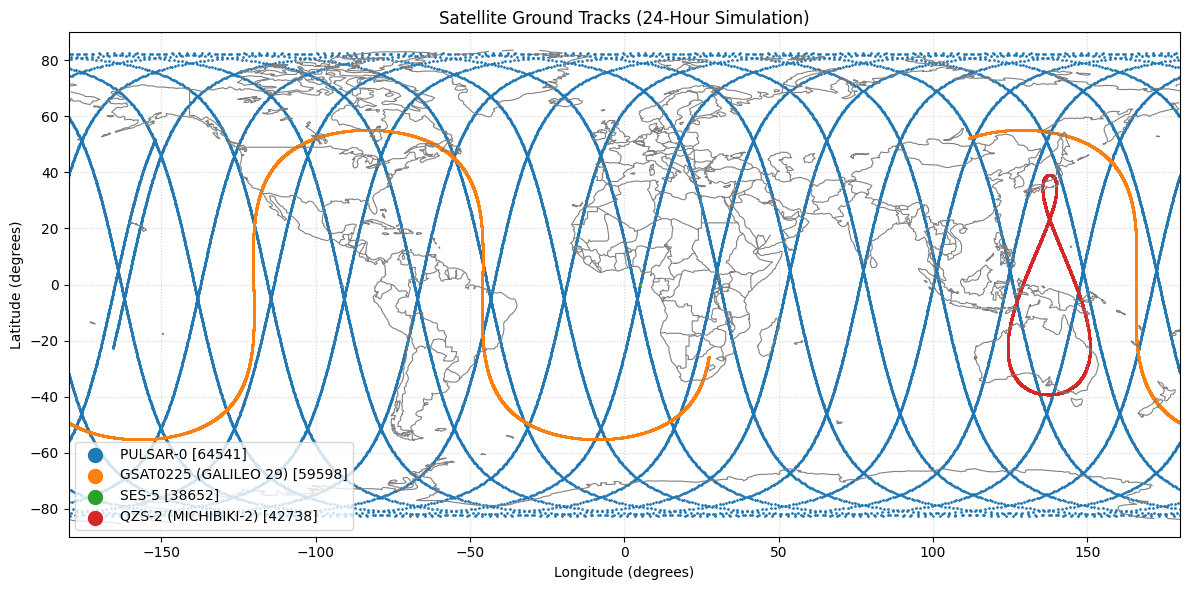

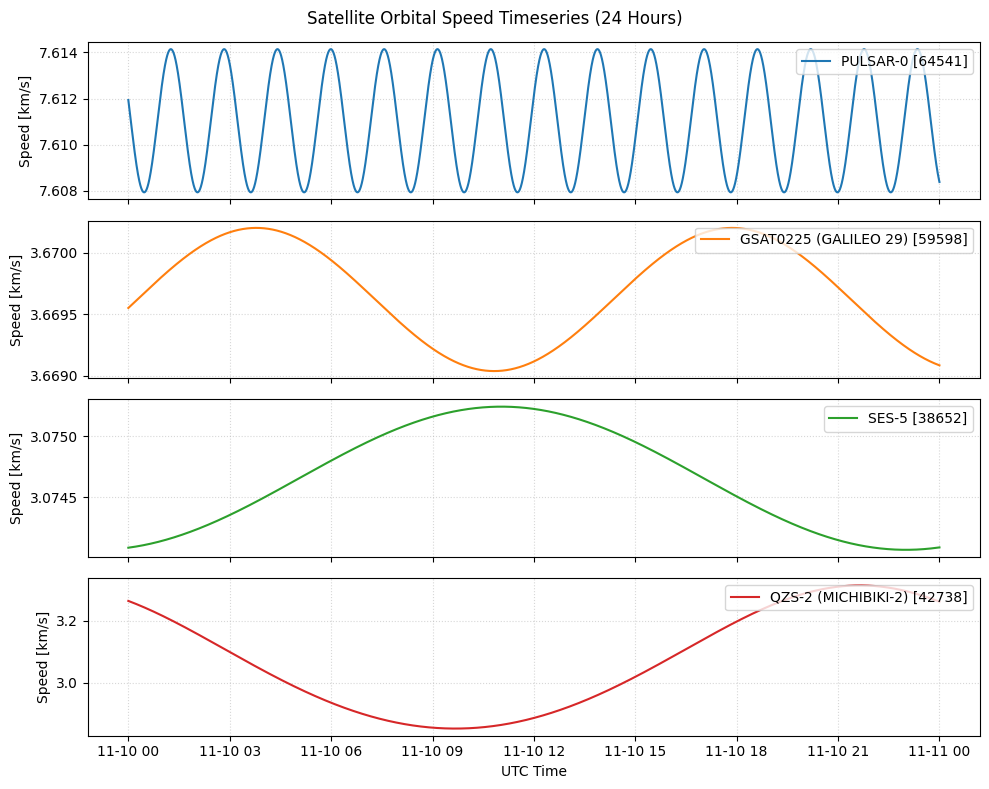


--- Stage 7: Matplotlib Plotting Success ---
Ground tracks and velocity timeseries plots generated and saved.


In [41]:
# Stage 7: Plots with Matplotlib (no Cartopy)

def load_coastline(path):
    """
    Loads coastline coordinates from world_map.txt.
    Each line contains 'latitude longitude' (latitude first).
    Blank lines separate distinct segments.
    """
    segments = []
    current_segment = []
    with open(path, 'r') as f:
        for line in f:
            stripped = line.strip()
            if not stripped:
                if current_segment:
                    segments.append(current_segment)
                    current_segment = []
            else:
                parts = stripped.split()
                if len(parts) == 2:
                    lat = float(parts[0])
                    lon = float(parts[1])
                    current_segment.append((lon, lat))
        if current_segment:
            segments.append(current_segment)
    return segments

# Configure global colors
COLORS = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']

if 'elements' in globals() and 'tracks' in globals():
    # Load coastline segments
    map_path = IN_DIR / 'world_map.txt'
    coastlines = load_coastline(map_path)

    # --- Figure 1: Ground Tracks Plot ---
    plt.figure(figsize=(12, 6))

    # Plot coastlines in gray
    for seg in coastlines:
        lons, lats = zip(*seg)
        plt.plot(lons, lats, color='gray', linewidth=0.8)

    # Scatter satellite ground tracks
    for idx, (el, track) in enumerate(zip(elements, tracks)):
        track_lons = [pt['lon_deg'] for pt in track]
        track_lats = [pt['lat_deg'] for pt in track]
        color = COLORS[idx % len(COLORS)]
        plt.scatter(track_lons, track_lats, s=1, color=color, label=el['label'])

    plt.title("Satellite Ground Tracks (24-Hour Simulation)")
    plt.xlabel("Longitude (degrees)")
    plt.ylabel("Latitude (degrees)")
    plt.xlim(-180, 180)
    plt.ylim(-90, 90)
    plt.grid(True, linestyle=':', alpha=0.5)
    plt.legend(loc='lower left', markerscale=10)

    plt.tight_layout()
    plt.savefig(OUT_DIR / 'ground_tracks.png', dpi=200)
    plt.show()

    # --- Figure 2: Velocity Timeseries Plot ---
    fig, axes = plt.subplots(len(elements), 1, figsize=(10, 8), sharex=True)

    for idx, (el, track) in enumerate(zip(elements, tracks)):
        ax = axes[idx]
        times_utc = [pt['time'] for pt in track]
        speeds = [pt['speed_km_s'] for pt in track]
        color = COLORS[idx % len(COLORS)]

        ax.plot(times_utc, speeds, color=color, label=el['label'])
        ax.set_ylabel("Speed [km/s]")
        ax.grid(True, linestyle=':', alpha=0.5)
        ax.legend(loc='upper right')
        ax.get_yaxis().get_major_formatter().set_useOffset(False)

    axes[-1].set_xlabel("UTC Time")
    plt.suptitle("Satellite Orbital Speed Timeseries (24 Hours)", y=0.98)
    plt.tight_layout()
    plt.savefig(OUT_DIR / 'velocity_timeseries.png')
    plt.show()

    print("\n--- Stage 7: Matplotlib Plotting Success ---")
    print("Ground tracks and velocity timeseries plots generated and saved.")
else:
    print("Error: dependencies 'elements' or 'tracks' not found in namespace.")

In [42]:
# Stage 8: Export for Google Earth and Write the Report

# Register KML Namespaces
ET.register_namespace('', "http://www.opengis.net/kml/2.2")
ET.register_namespace('gx', "http://www.google.com/kml/ext/2.2")

def hex_to_kml_color(hex_str):
    """
    Converts a standard hex color string or Matplotlib color name to aabbggrr KML format.
    e.g., '#1f77b4' -> 'ffb4771f'
    """
    rgba = mcolors.to_rgba(hex_str)
    # Extracted values in 0-255 range
    r = int(rgba[0] * 255)
    g = int(rgba[1] * 255)
    b = int(rgba[2] * 255)
    a = int(rgba[3] * 255)
    return f"{a:02x}{b:02x}{g:02x}{r:02x}"

def build_ecef_kml(elements_list, tracks_list, path):
    """
    Generates an ECEF 3D orbit track KML file.
    """
    kml = ET.Element("kml", xmlns="http://www.opengis.net/kml/2.2")
    doc = ET.SubElement(kml, "Document")

    title = ET.SubElement(doc, "name")
    title.text = "Multi-Satellite Orbits | Earth-fixed"

    # Generate Styles
    for idx, el in enumerate(elements_list):
        color_hex = hex_to_kml_color(COLORS[idx % len(COLORS)])

        style = ET.SubElement(doc, "Style", id=f"style_{el['norad_id']}")

        icon_style = ET.SubElement(style, "IconStyle")
        icon_color = ET.SubElement(icon_style, "color")
        icon_color.text = color_hex
        icon = ET.SubElement(icon_style, "Icon")
        href = ET.SubElement(icon, "href")
        href.text = "http://maps.google.com/mapfiles/kml/shapes/placemark_circle.png"

        line_style = ET.SubElement(style, "LineStyle")
        line_color = ET.SubElement(line_style, "color")
        line_color.text = color_hex
        width = ET.SubElement(line_style, "width")
        width.text = "3"

    # Generate Placemarks
    for idx, (el, track) in enumerate(zip(elements_list, tracks_list)):
        pm = ET.SubElement(doc, "Placemark")
        pm_name = ET.SubElement(pm, "name")
        pm_name.text = el['name']

        style_url = ET.SubElement(pm, "styleUrl")
        style_url.text = f"#style_{el['norad_id']}"

        ls = ET.SubElement(pm, "LineString")
        alt_mode = ET.SubElement(ls, "altitudeMode")
        alt_mode.text = "absolute"

        coords = ET.SubElement(ls, "coordinates")
        coord_strings = []
        for pt in track:
            coord_strings.append(f"{pt['lon_deg']:.6f},{pt['lat_deg']:.6f},{pt['alt_km']*1000.0:.1f}")
        coords.text = " ".join(coord_strings)

    tree = ET.ElementTree(kml)
    tree.write(path, encoding="utf-8", xml_declaration=True)

def build_animation_kml(elements_list, tracks_list, path):
    """
    Generates a time-animated ground track KML file using gx:MultiTrack.
    """
    kml = ET.Element("kml", xmlns="http://www.opengis.net/kml/2.2", xmlns_gx="http://www.google.com/kml/ext/2.2")
    doc = ET.SubElement(kml, "Document")

    title = ET.SubElement(doc, "name")
    title.text = "Multi-Satellite Ground Tracks | Animation"

    # Generate Styles
    for idx, el in enumerate(elements_list):
        color_hex = hex_to_kml_color(COLORS[idx % len(COLORS)])

        style = ET.SubElement(doc, "Style", id=f"style_{el['norad_id']}")

        icon_style = ET.SubElement(style, "IconStyle")
        icon_color = ET.SubElement(icon_style, "color")
        icon_color.text = color_hex
        icon = ET.SubElement(icon_style, "Icon")
        href = ET.SubElement(icon, "href")
        href.text = "http://maps.google.com/mapfiles/kml/shapes/placemark_circle.png"

        line_style = ET.SubElement(style, "LineStyle")
        line_color = ET.SubElement(line_style, "color")
        line_color.text = color_hex
        width = ET.SubElement(line_style, "width")
        width.text = "2"

    # Generate Placemarks with tracks
    for idx, (el, track) in enumerate(zip(elements_list, tracks_list)):
        pm = ET.SubElement(doc, "Placemark")
        pm_name = ET.SubElement(pm, "name")
        pm_name.text = el['name']

        style_url = ET.SubElement(pm, "styleUrl")
        style_url.text = f"#style_{el['norad_id']}"

        multitrack = ET.SubElement(pm, "gx:MultiTrack")

        # Filter points to 60-second intervals (every 12th point in a 5s-grid)
        filtered_points = track[::12]

        # Split tracks on longitudinal boundary crossovers (>180 degree shifts)
        sub_tracks = []
        current_sub = []

        for i, pt in enumerate(filtered_points):
            if current_sub:
                prev_lon = current_sub[-1]['lon_deg']
                current_lon = pt['lon_deg']
                if abs(current_lon - prev_lon) > 180.0:
                    sub_tracks.append(current_sub)
                    current_sub = []
            current_sub.append(pt)
        if current_sub:
            sub_tracks.append(current_sub)

        for sub in sub_tracks:
            gx_track = ET.SubElement(multitrack, "gx:Track")
            alt_mode = ET.SubElement(gx_track, "altitudeMode")
            alt_mode.text = "clampToGround"

            # Timestamps
            for pt in sub:
                when = ET.SubElement(gx_track, "when")
                when.text = pt['time'].strftime('%Y-%m-%dT%H:%M:%SZ')

            # Coords
            for pt in sub:
                coord = ET.SubElement(gx_track, "gx:coord")
                coord.text = f"{pt['lon_deg']:.6f} {pt['lat_deg']:.6f} 0"

    tree = ET.ElementTree(kml)
    tree.write(path, encoding="utf-8", xml_declaration=True)

# Run KML Exports and write report
if 'elements' in globals() and 'tracks' in globals():
    # 1. Build KML outputs
    ecef_path = OUT_DIR / 'orbit_tracks_ecef.kml'
    anim_path = OUT_DIR / 'orbit_animation.kml'

    build_ecef_kml(elements, tracks, ecef_path)
    build_animation_kml(elements, tracks, anim_path)

    # 2. Compile and save the report
    report_path = OUT_DIR / 'orbit_report.txt'
    with open(report_path, 'w') as f:
        f.write("Satellite Orbit Report - built during Space Career Week 2026, GNSS Academy\n")
        f.write(f"{source_note}\n")
        f.write(f"Simulation Window: {start} to {end} | Step Size: {STEP_SECONDS} s\n")
        f.write("Model Caveat: Coordinates are calculated via a simplified two-body Keplerian model rotated using analytical GMST.\n\n")
        f.write("=== Orbit Summary Table ===\n")
        for line in summary_table(summaries):
            f.write(line + "\n")
        f.write("\n=== Keplerian Initial Elements Table ===\n")
        for line in elements_table(elements):
            f.write(line + "\n")

    # 3. Zip all Stage 7 and 8 outputs
    zip_path = OUT_DIR / 'satellite_orbit_outputs.zip'
    files_to_zip = [
        OUT_DIR / 'ground_tracks.png',
        OUT_DIR / 'velocity_timeseries.png',
        ecef_path,
        anim_path,
        report_path
    ]

    with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zip_ref:
        for file in files_to_zip:
            if file.exists():
                zip_ref.write(file, arcname=file.name)

    print("\n--- Stage 8: Export Completed Successfully ---")
    print(f"Created and verified KML files:")
    print(f"  - ECEF 3D Tracks KML: {ecef_path.name}")
    print(f"  - Time-Animated Ground Tracks KML: {anim_path.name}")
    print(f"Saved final report text: {report_path.name}")
    print(f"Packaged outputs into archive: {zip_path.name}")

    # 4. Trigger the download automatically
    print("\nDownloading 'satellite_orbit_outputs.zip' to your local machine...")
    files.download(str(zip_path))
else:
    print("Error: Dependencies from previous stages are missing.")


--- Stage 8: Export Completed Successfully ---
Created and verified KML files:
  - ECEF 3D Tracks KML: orbit_tracks_ecef.kml
  - Time-Animated Ground Tracks KML: orbit_animation.kml
Saved final report text: orbit_report.txt
Packaged outputs into archive: satellite_orbit_outputs.zip



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [43]:
# Optional extension: Live CelesTrak Data

def load_live_celestrak_data():
    """
    Downloads and caches live CelesTrak GP JSON elements if LIVE_GROUP is specified.
    Respects API rate limits with a 2-hour local caching threshold.
    """
    global sats, source_note

    if LIVE_GROUP is None:
        print("LIVE_GROUP is None. Using the default offline workshop elements snapshot.")
        return

    cache_path = IN_DIR / f"gp_{LIVE_GROUP}.json"
    cache_duration = timedelta(hours=2)
    should_download = True

    # Check if a valid, recent cache exists to protect CelesTrak servers
    if cache_path.exists():
        mtime = datetime.fromtimestamp(cache_path.stat().st_mtime, tz=timezone.utc)
        age = datetime.now(timezone.utc) - mtime
        if age < cache_duration:
            should_download = False
            print(f"Using cached live data from {cache_path.name} (age: {age.total_seconds()/60:.1f} minutes).")

    if should_download:
        url = f"https://celestrak.org/NORAD/elements/gp.php?GROUP={LIVE_GROUP}&FORMAT=JSON"
        print(f"Downloading live CelesTrak data for group '{LIVE_GROUP}'...")
        try:
            response = requests.get(url, timeout=30)
            response.raise_for_status()
            data = response.json()

            # Basic structure sanity check
            if not isinstance(data, list) or len(data) == 0:
                raise ValueError("Received empty or invalid JSON structure from CelesTrak API.")

            # Cache valid response locally
            with open(cache_path, 'w') as f:
                json.dump(data, f, indent=2)
            print(f"Successfully saved fresh CelesTrak data to cache: {cache_path.name}")
        except Exception as e:
            if cache_path.exists():
                print(f"API download failed due to: {e}. Falling back to existing cached file.")
            else:
                raise RuntimeError(f"Failed to download live group '{LIVE_GROUP}' and no cache is available: {e}")

    # Load, validate, sort, and slice down to the first four spacecraft
    all_records = read_gp_json(cache_path)
    sorted_records = sorted(all_records, key=lambda x: int(x['NORAD_CAT_ID']))
    selected_sats = sorted_records[:4]

    # Update global variables
    sats = selected_sats
    retrieval_time = datetime.fromtimestamp(cache_path.stat().st_mtime, tz=timezone.utc)
    source_note = f"Live data for group '{LIVE_GROUP}' retrieved from CelesTrak cache (Modified UTC: {retrieval_time.strftime('%Y-%m-%d %H:%M:%SZ')})"

    print(f"\n--- Live CelesTrak Data Loaded for Group: {LIVE_GROUP} ---")
    print(source_note)
    print(f"Selected the first {len(sats)} satellites sorted by NORAD ID:")
    for sat in sats:
        print(f"  - Name: {sat['OBJECT_NAME']} | NORAD ID: {sat['NORAD_CAT_ID']} | Epoch: {sat['EPOCH']}")

# Run Live CelesTrak Data loading logic
if 'IN_DIR' in globals() and 'read_gp_json' in globals():
    load_live_celestrak_data()
else:
    print("Error: dependencies from Stages 1 or 2 are missing.")

Using cached live data from gp_GALILEO.json (age: 94.7 minutes).

--- Live CelesTrak Data Loaded for Group: GALILEO ---
Live data for group 'GALILEO' retrieved from CelesTrak cache (Modified UTC: 2026-11-17 10:10:45Z)
Selected the first 4 satellites sorted by NORAD ID:
  - Name: GSAT0101 (GALILEO-PFM) | NORAD ID: 37846 | Epoch: 2026-11-16T22:43:45.278112
  - Name: GSAT0102 (GALILEO-FM2) | NORAD ID: 37847 | Epoch: 2026-11-16T07:01:30.302112
  - Name: GSAT0103 (GALILEO-FM3) | NORAD ID: 38857 | Epoch: 2026-11-15T19:33:47.133504
  - Name: GSAT0201 (GALILEO 5) | NORAD ID: 40128 | Epoch: 2026-11-16T22:47:45.972960


In [44]:
# Load and view the cached CelesTrak live JSON data

cache_file = IN_DIR / f'gp_{LIVE_GROUP}.json'

if cache_file.exists():
    print(f"Reading CelesTrak cache: {cache_file.name}\n")
    with open(cache_file, 'r') as f:
        cache_data = json.load(f)

    # Display the total records and a formatted sample of the first satellite
    print(f"Total satellites found in cached group: {len(cache_data)}")
    print("\n--- Sample Satellite Record from Cache ---")
    print(json.dumps(cache_data[0], indent=2))
else:
    print(f"No cached file found at {cache_file}. Please make sure you have executed the retrieval cell.")

Reading CelesTrak cache: gp_GALILEO.json

Total satellites found in cached group: 32

--- Sample Satellite Record from Cache ---
{
  "OBJECT_NAME": "GSAT0101 (GALILEO-PFM)",
  "OBJECT_ID": "2011-060A",
  "EPOCH": "2026-11-16T22:43:45.278112",
  "MEAN_MOTION": 1.70475764,
  "ECCENTRICITY": 0.0002309,
  "INCLINATION": 56.9324,
  "RA_OF_ASC_NODE": 337.6112,
  "ARG_OF_PERICENTER": 311.6095,
  "MEAN_ANOMALY": 48.4124,
  "EPHEMERIS_TYPE": 0,
  "CLASSIFICATION_TYPE": "U",
  "NORAD_CAT_ID": 37846,
  "ELEMENT_SET_NO": 999,
  "REV_AT_EPOCH": 9372,
  "BSTAR": 0,
  "MEAN_MOTION_DOT": -5.8e-07,
  "MEAN_MOTION_DDOT": 0
}
